In [88]:
import pandas as pd
df = pd.read_csv("../data/raw_influencers.csv")
print(df.shape)


(100, 13)


In [89]:
df.head()

,channel_id,name,url,country,description,subscribers,video_count,total_view,uploads_id,recent_likes,recent_comments,recent_views,recent_titles
0,UCu7Ld2o0QnLPm4j0gCn7Agw,SHEF,https://youtube.com/channel/UCu7Ld2o0QnLPm4j0g...,IN,Description\nHello everyone! It's me Shef. I a...,1760000,678,1093087785,UUu7Ld2o0QnLPm4j0gCn7Agw,61231.0,1574.0,2365361.0,Skincare i do when i get Breakouts 🥲 #skincare...
1,UCeHzl7yBvyu3HalVxQScdhg,Madhuri Dixit Nene,https://youtube.com/channel/UCeHzl7yBvyu3HalVx...,IN,"Hi Guys,\nAll my fans hold a special place in ...",1300000,88,107129769,UUeHzl7yBvyu3HalVxQScdhg,72543.0,2755.0,4500058.0,PANCHAK - OFFICIAL TRAILER2 | MADHURI DIXIT NE...
2,UCMTl80jTQwGkO335HoVf0ig,Dr. Aanchal MD,https://youtube.com/channel/UCMTl80jTQwGkO335H...,IN,"Hi, I am a dermatologist and hair transplant s...",3500000,1001,1264679013,UUMTl80jTQwGkO335HoVf0ig,6786.0,439.0,597697.0,5 Popular Moisturizers for Oily Skin | Dermato...
3,UCPpjp_MTSIOaIgSh7FGFNUA,Daily skincare routine,https://youtube.com/channel/UCPpjp_MTSIOaIgSh7...,NaN,"I AM DR NIDA KHAN\n\nHi, I’m a Dermatologist (...",59,127,36423,UUPpjp_MTSIOaIgSh7FGFNUA,16.0,0.0,1291.0,28 August 2026 | 30 July 2026 | 28 January 202...
4,UCkdh75lQUkRHIC18GhUFY-Q,Shan khan,https://youtube.com/channel/UCkdh75lQUkRHIC18G...,IN,"Hey, I’m Shan Khan!\nFor business 👉 contact.sh...",2830000,255,1885759706,UUkdh75lQUkRHIC18GhUFY-Q,1131895.0,10112.0,40741474.0,Transforming my mom into a 90s 🥹 #trending #fa...


In [90]:
print(df.isnull().sum())
df["country"] = df["country"].fillna("Unknown")
df["description"] = df["description"].fillna(" ")
df["recent_likes"] = df["recent_likes"].fillna(df["recent_likes"].mean())
df["recent_views"] = df["recent_views"].fillna(df["recent_views"].mean())
df["recent_titles"] = df["recent_titles"].fillna("Unknown")

channel_id          0
name                0
url                 0
country            39
description        15
subscribers         0
video_count         0
total_view          0
uploads_id          0
recent_likes        3
recent_comments     3
recent_views        3
recent_titles       3
dtype: int64


In [92]:
cols = ["recent_likes","recent_comments","recent_views"]
for c in cols:
    df[c] = pd.to_numeric(df[c] , errors = "coerce")
    df[c] = df[c].fillna(df[c].median())
print(df[cols].isnull().sum())
print(df[cols].dtypes)

recent_likes       0
recent_comments    0
recent_views       0
dtype: int64
recent_likes       float64
recent_comments    float64
recent_views       float64
dtype: object


In [93]:
print(df["channel_id"].duplicated().sum())

0


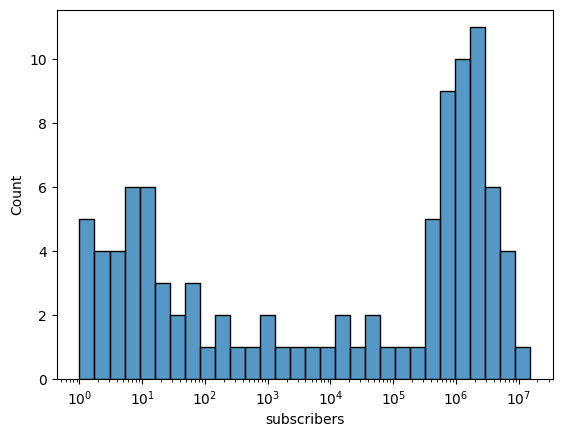

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(df["subscribers"], bins = 30,log_scale = True)
plt.savefig("../output/charts/subscribers_hist.png")
plt.show()




In [13]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [95]:
micro = df[df["subscribers"]. between(50000,10000000)]
print(len(micro) , "of" , len(df), "are-micro influencer")

49 of 100 are-micro influencer


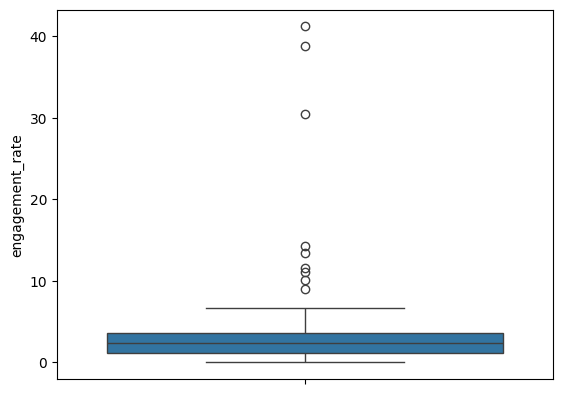

count    100.000000
mean       3.782839
std        6.465982
min        0.000000
25%        1.098785
50%        2.350269
75%        3.571996
max       41.176471
Name: engagement_rate, dtype: float64


In [96]:
df["engagement_rate"] =( df["recent_likes"] + df["recent_comments"]) / df["recent_views"] * 100
sns.boxplot(df["engagement_rate"])
plt.savefig("../output/charts/subscribers_hist.png")
plt.show()
print(df["engagement_rate"].describe())

In [112]:
import sys
sys.path.append("../src")
import importlib, filters
importlib.reload(filters)
from filters import apply_filters

df = pd.read_csv("../data/processed_influencers.csv")
out = apply_filters(df)
print(out["result"].value_counts())
print(out["fail_reason"].value_counts().head(10))
out.to_csv("../data/filtered_influencers.csv", index=False)

result
Fail    94
Pass     6
Name: count, dtype: int64
fail_reason
follwers too low                                                 24
follwers too low; country mismatch                               16
country mismatch                                                 13
country mismatch; niche_mismatch                                 10
follwers too low; engagememt rate low/missing                     7
                                                                  6
engagememt rate low/missing; country mismatch; niche_mismatch     6
engagememt rate low/missing; country mismatch                     5
engagememt rate low/missing                                       3
follwers too low; country mismatch; niche_mismatch                3
Name: count, dtype: int64
